# 9주차 · 기본 정렬 구현 및 비교
## 학생 배포용: TODO 구현·테스트·성능 실험
데이터구조 | 임화정 | Python 3.8+

학습목표: 버블·선택·삽입 정렬을 구현하고, 불변식·안정성·시간/보조공간 복잡도를 설명하며 동일 입력의 성능을 측정한다.

강의계획서의 9주차 목표와 2주차 Big-O, 7주차 BST/TreeSort를 연결한다. 기존 자료의 개념→구현→검증→성능 분석 흐름을 따른다.

사용법: 위에서 아래로 실행한다. 학생용은 미구현 함수를 안내하고 해당 실험을 건너뛴다. TODO 완료 뒤 구현·테스트·실험 셀을 다시 실행한다.

권장 150분 수업: 개념/추적 50분, 구현 45분, 실험 35분, 토론/정리 20분(휴식 별도).

In [9]:
import random
import time
import statistics
import csv
from collections import Counter
SEED = 2026
# Python 3.8+ / Colab / Jupyter. 그래프 셀만 matplotlib가 필요합니다.
print("9주차 실습 준비 완료")

9주차 실습 준비 완료


## 1. 공통 인터페이스와 사전 예측
`sort(a, key=lambda x:x)`는 리스트 자체를 오름차순으로 변경하고 동일한 리스트를 반환한다. 반환값 복사 금지. `sorted`/`list.sort`는 구현에 사용하지 않고 정답 검증에만 사용한다.

버블은 인접 교환, 선택은 최소값 선택, 삽입은 정렬된 접두부에 삽입한다. 핵심 구현의 보조공간은 O(1); 실험용 복사·추적 기록은 별도 O(n) 이상이다. key 호출/비교는 O(1)이라고 가정한다.

**예측**: 이미 정렬된 입력에 가장 유리한 것은? 선택 정렬도 빨라질까?

**내답**: 삽입 정렬과 버블 정렬이 이미 정렬된 입력에 유리하다. 두 알고리즘 모두 배열이 이미 정렬된 상태라면 불필요한 교환이나 이동 없이 한 번의 순회만으로 정렬이 완료되었음을 파악할 수 있다. / 선택 정렬은 빨라지지 않는다. 선택 정렬은 현재 위치에 들어갈 최솟값을 찾기 위해 항상 끝까지 탐색해야 하므로 비교 연산 횟수는 항상 고정되어 있다.

## bubble_sort 구현
각 패스 뒤 최댓값이 오른쪽에 확정됩니다. end를 줄이고 교환이 없으면 종료. > 비교는 동점 순서를 유지합니다.

In [10]:
def bubble_sort(a, key=lambda x: x):
    # TODO: 위 설명과 슬라이드의 불변식을 참고하여 구현
    for end in range(len(a) - 1, 0, -1):
      swapped = False
      for j in range(end):
        if key(a[j]) > key(a[j+1]):
          a[j], a[j+1] = a[j+1], a[j]
          swapped = True
      if not swapped:
        break
    return a

## selection_sort 구현
i 이전 접두부가 확정됩니다. min_idx를 i로 초기화하고 나머지 구간을 모두 비교합니다. 최솟값과 한 번 교환. 일반 교환형 선택 정렬은 불안정합니다.

In [11]:
def selection_sort(a, key=lambda x: x):
    # TODO: 위 설명과 슬라이드의 불변식을 참고하여 구현
    for i in range(len(a) - 1):
      min_idx = i
      for j in range(i + 1, len(a)):
        if key(a[j]) < key(a[min_idx]):
          min_idx = j
      if min_idx != i:
        a[i], a[min_idx] = a[min_idx], a[i]
    return a

## insertion_sort 구현
a[:i]가 정렬되어 있습니다. current를 저장하고 큰 원소만 오른쪽으로 이동합니다. j >= 0을 먼저 검사하여 음수 인덱스 접근을 막습니다.

In [12]:
def insertion_sort(a, key=lambda x: x):
    # TODO: 위 설명과 슬라이드의 불변식을 참고하여 구현
    for i in range(1, len(a)):
      current = a[i]
      j = i-1
      while j >= 0 and key(a[j]) > key(current):
        a[j+1] = a[j]
        j -= 1
      a[j+1] = current
    return a

## 2. 정확성 검사
빈 입력·단일 원소·중복·음수·정렬/역순·고정 시드 무작위 입력. 결과 순서와 원소 보존, in-place 반환 계약을 확인한다.

In [13]:
algorithms = {"Bubble": bubble_sort, "Selection": selection_sort, "Insertion": insertion_sort}
def test_sort(fn):
    cases = [[], [1], [2, 1], [1, 2, 3], [3, 2, 1], [2, 2, 1, 2], [-3, 0, -1, 5]]
    rng = random.Random(SEED)
    cases += [[rng.randrange(-20, 21) for _ in range(n)] for n in range(41)]
    for original in cases:
        a = original.copy()
        returned = fn(a)
        assert returned is a, "반환값은 입력 리스트 자체여야 합니다."
        assert a == sorted(original), (original, a)
        assert Counter(a) == Counter(original)
    return len(cases)
ready = {}
for name, fn in algorithms.items():
    try:
        print(name, test_sort(fn), "개 테스트 통과")
        ready[name] = fn
    except NotImplementedError:
        print(name, "TODO 구현 후 이 셀을 다시 실행하세요.")
assert len(ready) in range(4)

Bubble 48 개 테스트 통과
Selection 48 개 테스트 통과
Insertion 48 개 테스트 통과


## 3. 패스 추적
[5, 1, 4, 2, 8]의 각 패스 결과를 먼저 손으로 작성하라.
학생 답안: 버블 [5, 1, 4, 2, 8] -> [1, 4, 2, 5, 8] -> [1, 2, 4, 5, 8] -> [1, 2, 4, 5, 8] (조기종료) / 선택 [5, 1, 4, 2, 8] -> [1, 5, 4, 2, 8] -> [1, 2, 4, 5, 8] -> [1, 2, 4, 5, 8] -> [1, 2, 4, 5, 8] / 삽입 [5, 1, 4, 2, 8] -> [1, 5, 4, 2, 8] -> [1, 4, 5, 2, 8] -> [1, 2, 4, 5, 8] -> [1, 2, 4, 5, 8]

## 4. 안정성 실험
동일 키의 원래 상대 순서가 유지되는가? 아래 기록을 첫 번째 필드만으로 정렬하고 A/B 순서를 관찰하라. 선택 정렬이 불안정한 이유를 설명하라.

선택 정렬이 불안정한 이유는 최솟값을 찾아 현재 위치의 값과 멀리 떨어진 위치에서 교환이 일어나기 때문입니다.
실험에 주어진 [(2, "A"), (2, "B"), (1, "C")] 배열을 예로 들어 구체적인 동작 과정을 살펴보면 다음과 같습니다.
첫 번째 패스에서 배열 전체의 최솟값인 (1, "C")를 찾습니다.
이 최솟값을 첫 번째 자리에 있는 (2, "A")와 교환합니다.
그 결과 배열은 [(1, "C"), (2, "B"), (2, "A")]가 됩니다.
이 교환 과정에서 원래 (2, "B")보다 앞에 있던 (2, "A")가 뒤쪽으로 이동하게 됩니다. 결과적으로 동일한 키값(2)을 가진 A와 B의 원래 상대적인 순서(A → B)가 뒤바뀌게(B → A) 되므로, 선택 정렬은 동점 순서 유지가 보장되지 않는 불안정 정렬입니다.

In [14]:
records = [(2, "A"), (2, "B"), (1, "C")]
for name, fn in ready.items():
    a = records.copy()
    fn(a, key=lambda r: r[0])
    print(name, a, "동점 순서 유지:", [r[1] for r in a if r[0] == 2] == ["A", "B"])
# 튜플 전체가 아니라 첫 번째 필드만 비교해야 안정성을 검증할 수 있습니다.

Bubble [(1, 'C'), (2, 'A'), (2, 'B')] 동점 순서 유지: True
Selection [(1, 'C'), (2, 'B'), (2, 'A')] 동점 순서 유지: False
Insertion [(1, 'C'), (2, 'A'), (2, 'B')] 동점 순서 유지: True


## 5. 연산 횟수와 복잡도
아래 계측기는 키 비교만 comparisons로 센다. 인덱스 검사 제외. swap은 두 원소 교환 1회, shift는 삽입 정렬의 오른쪽 이동 1회다. swap과 shift는 서로 같은 비용 단위가 아니며 전체 쓰기 횟수도 아니다. 계측기 함수는 측정용 모형이며 실행 시간 비교에는 사용하지 않는다.

In [15]:
def count_operations(data, kind):
    a = data.copy()
    comparisons = swaps = shifts = 0
    n = len(a)
    if kind == "Bubble":
        for end in range(n - 1, 0, -1):
            changed = False
            for j in range(end):
                comparisons += 1
                if a[j] > a[j + 1]:
                    a[j], a[j + 1] = a[j + 1], a[j]
                    swaps += 1
                    changed = True
            if not changed: break
    elif kind == "Selection":
        for i in range(n - 1):
            m = i
            for j in range(i + 1, n):
                comparisons += 1
                if a[j] < a[m]: m = j
            if m != i:
                a[i], a[m] = a[m], a[i]
                swaps += 1
    elif kind == "Insertion":
        for i in range(1, n):
            current = a[i]
            j = i - 1
            while j >= 0:
                comparisons += 1
                if a[j] <= current: break
                a[j + 1] = a[j]
                shifts += 1
                j -= 1
            a[j + 1] = current
    else:
        raise ValueError(kind)
    assert a == sorted(data)
    return {"comparisons": comparisons, "swaps": swaps, "shifts": shifts}
for kind in algorithms:
    for label, data in [("sorted", list(range(8))), ("reverse", list(range(7, -1, -1)))]:
        print(kind, label, count_operations(data, kind))
assert count_operations(list(range(8)), "Bubble")["comparisons"] == 7
assert count_operations(list(range(8)), "Selection")["comparisons"] == 28
assert count_operations(list(range(7, -1, -1)), "Insertion")["shifts"] == 28

Bubble sorted {'comparisons': 7, 'swaps': 0, 'shifts': 0}
Bubble reverse {'comparisons': 28, 'swaps': 28, 'shifts': 0}
Selection sorted {'comparisons': 28, 'swaps': 0, 'shifts': 0}
Selection reverse {'comparisons': 28, 'swaps': 4, 'shifts': 0}
Insertion sorted {'comparisons': 7, 'swaps': 0, 'shifts': 0}
Insertion reverse {'comparisons': 28, 'swaps': 0, 'shifts': 28}


### 분석 질문
1. 선택 정렬 비교 횟수 n(n−1)/2를 유도하라.
2. 조기 종료 버블의 최선 Θ(n), 최악 Θ(n²)를 설명하라.
3. 삽입 정렬의 shift 횟수와 역전쌍 수의 관계는?
4. n=8 정렬/역순에서 각 비교·교환·이동 횟수를 기록하라.

학생 답안: 1. 선택 정렬은 전체 n개의 원소에 대해 각 패스마다 정렬되지 않은 부분의 최솟값을 찾는다.. 첫 번째 패스에서는 n-1번 비교하고, 두 번째 패스에서는 n-2번, 마지막 패스에서는 1번 비교한다. 따라서 총 비교 횟수는 (n-1) + (n-2) +....+ 1이 되며, 등차수열의 합 공식에 따라 총 비교 횟수는 n(n-1)/2가 된다.

2.조기 종료 조건(swapped = False)이 적용된 버블 정렬은 한 패스 동안 교환이 전혀 발생하지 않으면 이미 정렬된 것으로 간주하고 즉시 탈출한다. 최선:배열이 이미 정렬된 상태라면 첫 번째 패스에서 n-1번의 비교만 수행하고 교환 없이 즉시 루프를 종료하므로 O(n)이 된다. 최악: 배열이 역순인 경우 매 비교마다 교환이 일어나 조기 종료가 발생하지 않는다. 즉 끝까지 루프를 돌아 총 비교 횟수가 n(n-1)/2번 발생하므로 O(n^2)가 된다.

3.삽입 정렬의 shift(오른쪽 이동) 연산 횟수는 초기 배열에 존재하는 역전쌍(Inversion)의 개수와 정확히 일치한다. 역전쌍이란 배열에서 인덱스 순서는 i < j 이지만 값은 A[i] > A[j]인 쌍을 의미한다. 삽입하려는 원소가 제자리를 찾기 위해 자신보다 큰 원소들을 오른쪽으로 밀어낼 때, 정확히 그 원소와 얽힌 역전쌍의 수만큼 이동이 발생하기 때문이다.

4.Bubble (버블 정렬):
정렬 상태 (최선): 비교 7, 교환(swaps) 0, 이동(shifts) 0
역순 상태 (최악): 비교 28, 교환(swaps) 28, 이동(shifts) 0
Selection (선택 정렬):
정렬 상태 (최선): 비교 28, 교환(swaps) 0, 이동(shifts) 0
역순 상태 (최악): 비교 28, 교환(swaps) 4, 이동(shifts) 0
Insertion (삽입 정렬):
정렬 상태 (최선): 비교 7, 교환(swaps) 0, 이동(shifts) 0
역순 상태 (최악): 비교 28, 교환(swaps) 0, 이동(shifts) 28

## 6. 공정한 실행 시간 측정
5개 입력 유형 × 4개 크기 × 3개 알고리즘. 고정 시드·동일 데이터·실행 전 복사·워밍업·5회 반복·중앙값. 시계는 perf_counter_ns. 생성/복사/검증/I/O 비용 제외. 키 함수는 공통으로 사용하므로 키 호출 오버헤드가 포함된다. 시간이 작은 경우 잡음이 크다. 환경마다 수치는 달라지며 한 번의 실측으로 Big-O를 증명할 수 없다. 거의 정렬된 입력은 인접 교환으로 생성된다.

In [16]:
def make_data(n, pattern, seed):
    rng = random.Random(seed)
    if pattern == "random": return [rng.randrange(n * 10 + 1) for _ in range(n)]
    if pattern == "sorted": return list(range(n))
    if pattern == "reverse": return list(range(n - 1, -1, -1))
    if pattern == "duplicates": return [rng.randrange(5) for _ in range(n)]
    if pattern == "nearly_sorted":
        a = list(range(n))
        for _ in range(max(1, n // 20)):
            if n > 1:
                j = rng.randrange(n - 1)
                a[j], a[j + 1] = a[j + 1], a[j]
        return a
    raise ValueError(pattern)
SIZES = [100, 200, 400, 800]  # 처음에는 작게; 큰 n은 O(n²)로 오래 걸립니다.
PATTERNS = ["random", "sorted", "reverse", "nearly_sorted", "duplicates"]
REPEATS = 5
results = []
if len(ready) != 3:
    print("세 알고리즘 구현 및 테스트를 완료하면 성능 비교가 실행됩니다.")
else:
    for pattern in PATTERNS:
        for n in SIZES:
            data = make_data(n, pattern, SEED + n)
            expected = sorted(data)  # 정답 생성은 측정 밖
            rng = random.Random(SEED + n)
            samples = {name: [] for name in ready}
            for fn in ready.values(): fn(data.copy())  # 워밍업
            for _ in range(REPEATS):
                names = list(ready)
                rng.shuffle(names)  # 실행 순서 편향 완화
                for name in names:
                    a = data.copy()  # 복사 비용은 측정 제외
                    start = time.perf_counter_ns()
                    ready[name](a)
                    elapsed = time.perf_counter_ns() - start
                    assert a == expected  # 검증도 측정 제외
                    samples[name].append(elapsed / 1_000_000)
            for name, values in samples.items():
                results.append({"pattern": pattern, "n": n, "algorithm": name,
                                "median_ms": statistics.median(values),
                                "min_ms": min(values), "max_ms": max(values)})
    with open("benchmark.csv", "w", newline="", encoding="utf-8-sig") as f:
        writer = csv.DictWriter(f, fieldnames=list(results[0]))
        writer.writeheader(); writer.writerows(results)
    for row in results[:9]: print(row)
    print("전체 결과: week09_benchmark.csv", len(results), "행")

{'pattern': 'random', 'n': 100, 'algorithm': 'Bubble', 'median_ms': 0.757764, 'min_ms': 0.728175, 'max_ms': 0.843064}
{'pattern': 'random', 'n': 100, 'algorithm': 'Selection', 'median_ms': 0.538654, 'min_ms': 0.530633, 'max_ms': 0.60204}
{'pattern': 'random', 'n': 100, 'algorithm': 'Insertion', 'median_ms': 0.386321, 'min_ms': 0.369382, 'max_ms': 0.451032}
{'pattern': 'random', 'n': 200, 'algorithm': 'Bubble', 'median_ms': 2.96594, 'min_ms': 2.871253, 'max_ms': 4.726307}
{'pattern': 'random', 'n': 200, 'algorithm': 'Selection', 'median_ms': 2.052202, 'min_ms': 2.025874, 'max_ms': 2.722669}
{'pattern': 'random', 'n': 200, 'algorithm': 'Insertion', 'median_ms': 1.572308, 'min_ms': 1.511778, 'max_ms': 1.702099}
{'pattern': 'random', 'n': 400, 'algorithm': 'Bubble', 'median_ms': 12.040364, 'min_ms': 12.004636, 'max_ms': 12.208184}
{'pattern': 'random', 'n': 400, 'algorithm': 'Selection', 'median_ms': 8.885787, 'min_ms': 8.814674, 'max_ms': 9.112417}
{'pattern': 'random', 'n': 400, 'algorit

In [8]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 7. 성능 시각화
아래 그래프는 현재 실행에서 측정한 중앙값만 사용한다. 범례와 단위를 확인하고 유형별로 비교하라.

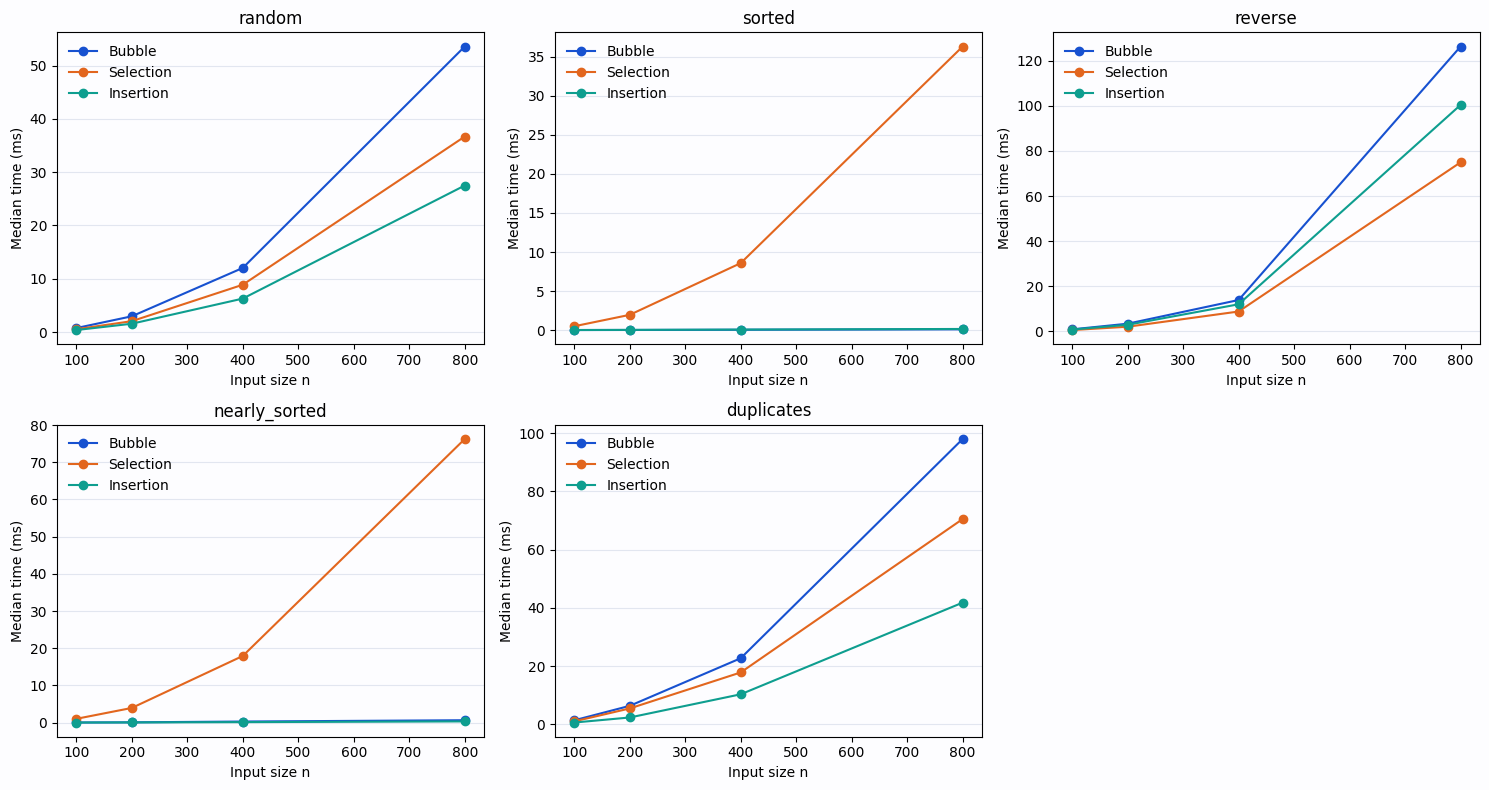

In [17]:
if results:
    try:
        import matplotlib.pyplot as plt
        try:
            import koreanize_matplotlib
        except ImportError:
            pass  # 그래프 라벨은 영문이므로 Colab에서도 실행 가능
        colors = ["#1751D0", "#E2661E", "#0E9E8F"]
        fig, axes = plt.subplots(2, 3, figsize=(15, 8), facecolor="#FDFDFF")
        for ax, pattern in zip(axes.flat, PATTERNS):
            ax.set_facecolor("#FDFDFF")
            for color, name in zip(colors, algorithms):
                rows = sorted([r for r in results if r["pattern"] == pattern and r["algorithm"] == name], key=lambda r:r["n"])
                ax.plot([r["n"] for r in rows], [r["median_ms"] for r in rows], marker="o", color=color, label=name)
            ax.set(title=pattern, xlabel="Input size n", ylabel="Median time (ms)")
            ax.grid(axis="y", color="#E2E6F0"); ax.set_axisbelow(True)
            ax.legend(frameon=False)
        axes.flat[-1].axis("off")
        fig.tight_layout()
        fig.savefig("benchmark.png", dpi=150)
        plt.show()
    except ImportError:
        print("matplotlib가 없어 그래프를 건너뜁니다. Colab에서 실행하거나 CSV를 활용하세요.")
else:
    print("구현 완료 후 성능 측정 셀부터 다시 실행하세요.")

## 8. 결과 분석 및 제출
- 무작위/역순에서 n을 두 배로 늘릴 때 시간 비율 T(2n)/T(n)은?
- 분석: 대략 4배입니다. 무작위 및 역순 입력(평균 및 최악의 경우)에서 버블, 선택, 삽입 정렬의 시간 복잡도는 모두 O(n^2)입니다. 따라서 입력 크기 n이 2배가 되면 연산량은 2^2 = 4배 증가하므로, 실행 시간 또한 약 4배 늘어납니다.

- 정렬 입력의 버블·삽입과 선택은 어떻게 다른가?
- 분석: 이미 정렬된 입력(최선의 경우)에서 조기 종료가 적용된 버블 정렬과 삽입 정렬은 원소의 위치 교환 및 이동 없이 1회 순회만으로 정렬을 마치므로 시간 복잡도가 O(n)으로 매우 빠릅니다. 반면 선택 정렬은 배열이 정렬되어 있더라도 현재 위치에 넣을 최솟값을 찾기 위해 남은 배열 전체를 끝까지 탐색해야 하므로 여전히 O(n^2)의 시간이 소요되어 상대적으로 매우 느립니다.

- 안정성과 이동 횟수는 어떤 문제에서 중요한가?
- 분석: 안정성: 다중 조건으로 데이터를 정렬할 때 중요합니다. (예: 엑셀에서 '나이'로 먼저 정렬한 후 '이름'으로 다시 정렬할 때, 같은 이름 안에서 나이 순서가 원래대로 유지되어야 하는 경우)
- 이동 횟수: 정렬하는 객체의 크기가 매우 커서 메모리 쓰기(Write) 및 복사 비용이 키(Key) 비교 연산 비용보다 압도적으로 높은 환경에서 중요합니다. 이런 경우 이동 연산이 적은 알고리즘이 유리합니다.

- nearly_sorted 결과를 역전쌍 관점에서 설명하라.
- 삽입 정렬의 데이터 오른쪽 이동(shift) 횟수는 배열 내에 존재하는 역전쌍(Inversion)의 개수와 정확히 일치합니다. nearly_sorted(거의 정렬된) 데이터는 초기 역전쌍의 개수가 O(n)에 가깝게 매우 적습니다. 따라서 삽입 정렬 시 데이터를 뒤로 미는 연산이 거의 발생하지 않아 시간 복잡도가 최선인 O(n)에 가깝게 동작하며, 세 알고리즘 중 가장 압도적인 성능을 보입니다.

- 이론과 실측이 다른 이유 2가지를 적어라.
1. 상수항과 오버헤드 무시: 이론적인 빅오(Big-O) 표기법은 함수 호출, 루프 제어, 변수 할당 등 실제 프로그램 구동 시 발생하는 상수항과 낮은 차수의 연산 오버헤드를 무시하기 때문입니다.
2. 하드웨어 및 시스템 최적화 요인: CPU 캐시 메모리의 지역성(Cache locality), 분기 예측(Branch prediction), 메모리 계층 구조, 그리고 OS의 백그라운드 프로세스 등 컴퓨터의 물리적/소프트웨어적 상태가 실제 측정 시간에 큰 영향을 미치기 때문입니다.

**답안**:

- 실측 표 요약: 무작위 및 역순 입력에서는 세 알고리즘 모두 데이터 증가에 따라 시간이 급증하나, 정렬/거의 정렬된 입력에서는 삽입과 버블 정렬이 선택 정렬보다 압도적으로 짧은 실행 시간을 기록함.
- 그래프 해석: n이 커질수록 무작위/역순 그래프는 y=x^2 형태의 포물선을 그리며 상승하지만, 정렬된 입력에서 버블과 삽입 정렬은 가로축에 붙은 y=x 형태의 완만한 직선을 그림.
- 복잡도 근거: 버블, 선택, 삽입 정렬의 최악 시간 복잡도는 모두 O(n^2)로 동일하지만, 최선(정렬됨)의 경우 버블과 삽입은 O(n), 선택은 O(n^2)로 이론적 복잡도 차이가 실측 시간 차이로 명확히 드러남.
- 선택 근거: 데이터가 이미 정렬에 가까운 상태라면 '삽입 정렬', 메모리 교환 비용이 막대하게 크다면 교환 횟수가 적은 '선택 정렬', 동점자의 원래 순서를 보장해야 한다면 '버블'이나 '삽입 정렬'을 상황에 맞게 선택해야 함.

제출: DS_09배포용.ipynb, benchmark.csv, benchmark.png, 분석문 포함.
lms 과제란에 제출

## 이론 요약 및 근거 자료
|알고리즘|최선|평균|최악|보조공간|안정성|
|---|---|---|---|---|---|
|버블(조기 종료)|Θ(n)|Θ(n²)|Θ(n²)|O(1)|안정|
|선택(교환형)|Θ(n²)|Θ(n²)|Θ(n²)|O(1)|불안정|
|삽입(이동형)|Θ(n)|Θ(n²)|Θ(n²)|O(1)|안정|
평균은 무작위 순열 등 일반적인 입력 가정. 본 주차 코드는 수업 목표에 맞춰 새로 작성하였다.

근거: 데이터구조 강의계획서(26-2) 2~3쪽, 02. 알고리즘 복잡도와 Big-O(성능 측정·시간/공간 구분), 07 이진 탐색 트리(BST)(불변식·트레이스·TreeSort·실측), 01/03/04/05/06 강의자료의 이론→Python 구현→검증 흐름.